# 33 · Thesis Future-work figure: DINOv2 on VFS directory images vs patent figures

One figure for the dissertation's Future-work paragraph (06_Conclusion.tex) and the numbers behind it. Thin driver over `src/thesis_dino_figure.py`; the same run as `scripts/thesis_dino_figure.py`.

- **Embeddings** (read, not recomputed): `dinov2-reg-large_518` (facebook/dinov2-with-registers-large, frozen, 518 px), written by extraction notebook 25 / `scripts/registers_experiment.py` on 2026-09-30.
- **Unit**: one vector per aircraft, layer 24 CLS. Patents: the exp3 main figure; VFS directory: the hero image.
- **Labels**: VFS = the directory's own 5 classes; patents = the author's G1 type mapped to the same 5 classes.
- **Writes** into `COPY_TO_OTHER_PC_2026-10-24_DINO/` (mirrors LaTeX_v15): `Figures/Future_work/dino_embedding_vfs_vs_patents.{pdf,png}` + `_points.csv`, `Data_for_writing/csv/dino_scores.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / 'config.yaml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src import thesis_dino_figure as T

OUT = T.OUT_DEFAULT
print(OUT)

/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/COPY_TO_OTHER_PC_2026-10-24_DINO


## 1 · Scores, UMAP, figure

kNN-5 balanced accuracy with the maker held out (resampling interval: 1 000 resamples of the aircraft), shuffled-label chance (200 shuffles), logistic probe (5 folds grouped by maker), cosine silhouette against 200 label shuffles. UMAP fitted per source with the same settings (n_neighbors 15, min_dist 0.1, cosine, 2 components, seed 42). About 1 minute on CPU.

In [2]:
R = T.run(OUT)
R['meta']

I0000 00:00:1792864574.811051 3822522 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


/home/vasco/anaconda3/envs/Finetune/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/vasco/anaconda3/envs/Finetune/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


{'tag': 'dinov2-reg-large_518',
 'matrix': 'L24 CLS',
 'umap': {'n_neighbors': 15,
  'min_dist': 0.1,
  'metric': 'cosine',
  'n_components': 2,
  'random_state': 42},
 'k': 5,
 'n_boot': 1000,
 'n_shuffle': 200,
 'n_sil_shuffle': 200,
 'seed': 42,
 'run_seconds': 58.3}

In [3]:
cols = ['source', 'label_set', 'n_images', 'n_classes', 'n_makers', 'knn5_bal_acc', 'interval_lo', 'interval_hi',
        'chance_1_over_k', 'chance_shuffled_p95', 'probe_bal_acc', 'silhouette', 'sil_shuffle_p95', 'class_counts']
R['table'][cols].round(3)

,source,label_set,n_images,n_classes,n_makers,knn5_bal_acc,interval_lo,interval_hi,chance_1_over_k,chance_shuffled_p95,probe_bal_acc,silhouette,sil_shuffle_p95,class_counts
0,vfs,5 directory classes,1157,5,523,0.563,0.532,0.596,0.200,0.218,0.662,-0.035,-0.011,VT 410; WM 332; LC 218; HB 114; ER 83
1,patents,5 directory classes,663,5,369,0.445,0.357,0.530,0.200,0.217,0.606,-0.009,-0.022,VT 381; LC 193; WM 50; HB 30; ER 9
2,patents,12 G1 types (codebook),663,12,369,0.235,0.192,0.278,0.083,0.096,0.362,-0.056,-0.060,SLC 184; TR 157; CVT 109; TW 59; MR 50; PTC 26...


## 2 · The figure (as the PDF goes into LaTeX_v15, 16 cm wide)

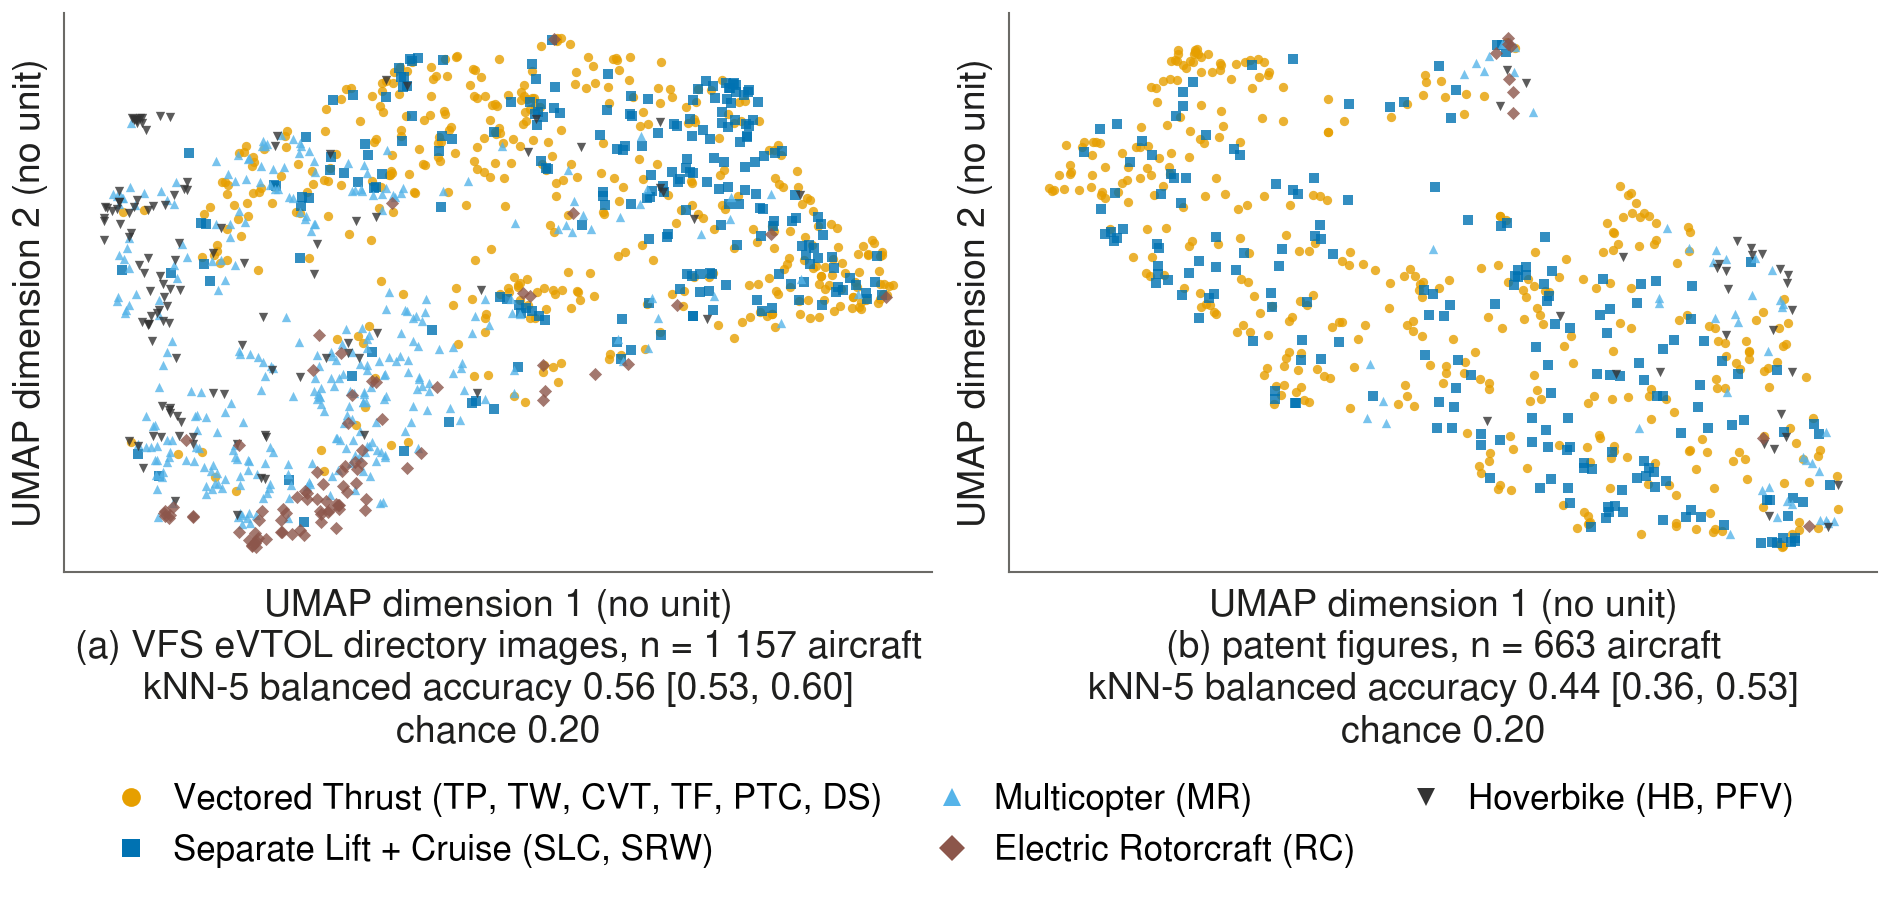

In [4]:
display(Image(filename=str(OUT / T.FIG_SUB / f'{T.NAME}.png'), width=900))

## 3 · Check against the saved protocol run

The kNN scores must equal `registers_check/registers_knn.csv` (L24 CLS rows).

In [5]:
saved = pd.read_csv(T.ER.PAT / '3_embedding_evaluation/registers_check/registers_knn.csv')
saved = saved[(saved.tag == T.REG_TAG) & (saved.matrix == 'L24 CLS')][['source', 'label', 'bal_acc', 'ci_lo', 'ci_hi']]
saved

,source,label,bal_acc,ci_lo,ci_hi
22,patents,G1 12-class,0.234598,0.192245,0.278089
28,patents,parent 5-class,0.444619,0.356627,0.530164
34,photos,5-class,0.563323,0.532306,0.595530
